# CS4100 — Data Cleaning & EDA for Popularity-Bias Recommenders
**Amazon Reviews 2023** · Popularity baseline · Item-CF · Matrix Factorization · Neural model

Run this notebook once per category (`All_Beauty` / `Beauty_and_Personal_Care`, `Amazon_Fashion`, `Clothing_Shoes_and_Jewelry`) by changing `CATEGORY`, then use Section 4 to compare categories side by side.

**Which fields actually matter**

| Need | Fields | Used by |
|---|---|---|
| Core interaction matrix | `user_id`, `parent_asin`, `rating`, `timestamp` | all 4 models |
| Relevance definition / filtering | `verified_purchase`, `rating` | evaluation |
| Popularity measurement | counts from reviews (+ `rating_number` from meta as a cross-check) | bias metrics |
| Context / side features | `main_category`, `store`, `price`, `categories`, `details` (brand) | EDA, optional neural features |
| Text | review `title`/`text`, item `title`/`features`/`description` | only if the neural model uses content |

Use **`parent_asin`** as the item ID everywhere: variants (size/colour) of one product share it, and metadata is keyed on it. `asin` would split one product into many "items" and fake a longer tail.

## 0. Setup & loading

In [19]:
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_DIR = Path(r"D:\CS4100\group project\popularity-bias-recsys\data\interim")
CATEGORY = "Beauty_and_Personal_Care"

REVIEW_PATH = DATA_DIR / f"{CATEGORY}_full.parquet" 
META_PATH   = DATA_DIR / f"{CATEGORY}_meta.parquet"

REVIEW_COLS = ["user_id", "parent_asin", "rating", "timestamp", "verified_purchase"]
META_COLS   = ["main_category", "parent_asin", "categories", "store", "price",
               "average_rating", "rating_number", "details"]

print("DATA_DIR:", DATA_DIR)
print("REVIEW_PATH exists:", REVIEW_PATH.exists())
print("META_PATH exists:  ", META_PATH.exists())

DATA_DIR: D:\CS4100\group project\popularity-bias-recsys\data\interim
REVIEW_PATH exists: True
META_PATH exists:   True


In [20]:
from pathlib import Path

DATA_DIR = Path(r"D:\CS4100\group project\popularity-bias-recsys\data\interim")

print("DATA_DIR:", DATA_DIR)
print("exists:", DATA_DIR.exists())
print("files:", [p.name for p in DATA_DIR.glob("*.parquet")])

DATA_DIR: D:\CS4100\group project\popularity-bias-recsys\data\interim
exists: True
files: ['Beauty_and_Personal_Care_dedup.parquet', 'Beauty_and_Personal_Care_full.parquet', 'Beauty_and_Personal_Care_meta.parquet']


In [21]:
import pyarrow as pa
import pyarrow.parquet as pq

def read_parquet_light(path, columns, batch_size=500_000):
    pf = pq.ParquetFile(path)
    chunks = []
    total = 0
    for batch in pf.iter_batches(batch_size=batch_size, columns=columns):
        df = batch.to_pandas()
        for col in df.columns:
            if df[col].dtype == "object":
                df[col] = df[col].astype("category")
        chunks.append(df)
        total += len(df)
        print(f"  read {total:,} rows", end="\r")
    print()
    return pd.concat(chunks, ignore_index=True)

reviews = read_parquet_light(REVIEW_PATH, REVIEW_COLS)
meta    = pd.read_parquet(META_PATH, columns=META_COLS)

print("reviews:", reviews.shape, "| meta:", meta.shape)
print(reviews.dtypes)
reviews.head()

  read 23,911,390 rows
reviews: (23911390, 5) | meta: (1028914, 8)
user_id                  str
parent_asin              str
rating               float64
timestamp              int64
verified_purchase    boolean
dtype: object


,user_id,parent_asin,rating,timestamp,verified_purchase
0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B00Z03RC80,1.0,1616743454733,True
1,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B085PRT2MP,1.0,1614915977684,True
2,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B08G81QQ9L,5.0,1612052493701,True
3,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B07YYG76X1,1.0,1609700981786,True
4,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B07X4FKLNK,3.0,1581313195358,True


## 1. Data cleaning

### 1.1 Types, ranges and missing values
**Why:** `timestamp` is Unix time in *milliseconds*; you need real datetimes for the temporal split. Ratings outside 1–5 or missing IDs would silently corrupt the user–item matrix.

In [22]:
reviews["timestamp"] = pd.to_datetime(reviews["timestamp"], unit="ms")
reviews["rating"] = pd.to_numeric(reviews["rating"], errors="coerce")

print("Date range:", reviews["timestamp"].min(), "->", reviews["timestamp"].max())
print("Ratings outside 1-5:", (~reviews["rating"].between(1, 5)).sum())
print("Missing values:\n", reviews.isna().sum())
# print("Empty review text:", (reviews["text"].fillna("").str.strip() == "").sum())

# IDs and rating are mandatory for every model
reviews = reviews.dropna(subset=["user_id", "parent_asin", "rating", "timestamp"])

Date range: 2000-04-01 08:10:29 -> 2023-09-13 16:30:23.621000
Ratings outside 1-5: 0
Missing values:
 user_id              0
parent_asin          0
rating               0
timestamp            0
verified_purchase    0
dtype: int64


### 1.2 Duplicate user–item interactions
**Why:** Item-CF and MF assume one cell per (user, item). The same user can review several variants of one parent product, or post exact duplicates. Duplicates inflate an item's popularity count and can leak into the test set. Keep the **latest** review per pair.

In [23]:
n0 = len(reviews)

# only calculate duplications 
n_exact_dup = reviews.duplicated().sum()

# only calculate duplications 
n_pair_dup = reviews.duplicated(["user_id", "parent_asin"], keep=False).sum()

print(f"rows: {n0:,}")
print(f"exact duplicate rows: {n_exact_dup:,} ({n_exact_dup/n0:.4%})")
print(f"rows in repeated (user, item) pairs: {n_pair_dup:,} ({n_pair_dup/n0:.4%})")

rows: 23,911,390
exact duplicate rows: 242,535 (1.0143%)
rows in repeated (user, item) pairs: 594,187 (2.4850%)


In [24]:
print("DATA_DIR   =", repr(DATA_DIR))
print("CATEGORY   =", repr(CATEGORY))
print("REVIEW_PATH=", repr(REVIEW_PATH))

DATA_DIR   = WindowsPath('D:/CS4100/group project/popularity-bias-recsys/data/interim')
CATEGORY   = 'Beauty_and_Personal_Care'
REVIEW_PATH= WindowsPath('D:/CS4100/group project/popularity-bias-recsys/data/interim/Beauty_and_Personal_Care_full.parquet')


In [25]:
import duckdb
from pathlib import Path

src = str(REVIEW_PATH).replace("\\", "/")
dst = str(DATA_DIR / f"{CATEGORY}_dedup.parquet").replace("\\", "/")

con = duckdb.connect()
con.execute(f"""
    COPY (
        SELECT user_id, parent_asin, rating, timestamp, verified_purchase
        FROM (
            SELECT *,
                   ROW_NUMBER() OVER (
                       PARTITION BY user_id, parent_asin
                       ORDER BY timestamp DESC
                   ) AS rn
            FROM read_parquet('{src}')
        )
        WHERE rn = 1
    ) TO '{dst}' (FORMAT PARQUET)
""")
con.close()

DEDUP_PATH = DATA_DIR / f"{CATEGORY}_dedup.parquet"
del reviews
gc.collect() 
reviews = read_parquet_light(DEDUP_PATH, REVIEW_COLS) 
reviews["timestamp"] = pd.to_datetime(reviews["timestamp"], unit="ms")
reviews = reviews.dropna(subset=["user_id", "parent_asin", "rating", "timestamp"])

print("saved to", dst)

  read 23,591,312 rows
saved to D:/CS4100/group project/popularity-bias-recsys/data/interim/Beauty_and_Personal_Care_dedup.parquet


### 1.3 Verified purchases
**Why:** Your proposal defines relevance as "did the user actually buy it". Unverified reviews may be gifts, free samples or incentivised reviews. Check how much data you'd lose before deciding to filter, and whether unverified reviews rate differently.

In [26]:
print(reviews["verified_purchase"].value_counts(normalize=True))
print(reviews.groupby("verified_purchase")["rating"].agg(["mean", "count"]))

pre_counts = reviews["parent_asin"].value_counts()

ONLY_VERIFIED = True   # decide as a team and keep it the same across categories
if ONLY_VERIFIED:
    reviews = reviews[reviews["verified_purchase"] == True].copy()
print("Rows kept:", len(reviews))

verified_purchase
True     0.911393
False    0.088607
Name: proportion, dtype: float64
                       mean     count
verified_purchase                    
False              4.115035   2090366
True               4.110747  21500946
Rows kept: 21500946


In [27]:
pre_head = set(pre_counts.cumsum()[pre_counts.cumsum() / pre_counts.sum() <= 0.2].index)

post_counts = reviews["parent_asin"].value_counts()
post_head = set(post_counts.cumsum()[post_counts.cumsum() / post_counts.sum() <= 0.2].index)

print("head items before:", len(pre_head))
print("head items after: ", len(post_head))
print("items lost from head:", len(pre_head - post_head))
print("items lost overall:", len(pre_counts) - len(post_counts))

head items before: 1501
head items after:  1392
items lost from head: 110
items lost overall: 61503


### 1.4 Metadata cleaning and join coverage
**Why:** `price` often arrives as a string or `"None"`; `store` and `main_category` have gaps; `details` is a dict you can mine for brand. Also check what share of reviewed items actually *have* metadata: any side-feature analysis only covers those.

In [28]:
import numpy as np

# drop duplication for meta
meta = meta.drop_duplicates("parent_asin")

# flattened fields cleaning 
meta["price"] = pd.to_numeric(meta["price"], errors="coerce")
meta["store"] = meta["store"].replace("", np.nan)

# Optional: Use regular expressions to directly extract the brand from the JSON string without parsing the entire dict
meta["brand"] = meta["details"].str.extract(r'"Brand"\s*:\s*"([^"]*)"', expand=False)
meta["brand"] = meta["brand"].fillna(
    meta["details"].str.extract(r'"brand"\s*:\s*"([^"]*)"', expand=False)
)

# Optional: Estimate the number of categories using the number of commas without parsing the list
meta["n_categories"] = meta["categories"].fillna("").str.count(",") + 1
meta.loc[meta["categories"].isna(), "n_categories"] = 0

# check lost 
print("Meta missing share:\n",
      meta[["main_category", "price", "store", "brand"]].isna().mean())

# Coverage: How many of the items that have been commented on are recorded in meta
reviewed_items = reviews["parent_asin"].unique()
coverage = meta["parent_asin"].isin(reviewed_items).mean()
print(f"Reviewed items with metadata: {coverage:.2%}")

Meta missing share:
 main_category    0.100004
price            0.630098
store            0.049288
brand            0.304385
dtype: float64
Reviewed items with metadata: 94.00%


### 1.5 Explicit ratings → implicit feedback
**Why:** The `implicit` library, the popularity baseline and top-K ranking metrics all work on implicit signals (did the user interact / like it?). Pick one definition and keep it fixed across models:
- **Option A:** every (verified) review is a positive interaction. Simple, and the most common choice in the literature.
- **Option B:** only ratings ≥ 4 are positives. Closer to "the user liked it", but drops data.

In [29]:
POSITIVE_THRESHOLD = None   # None = Option A
if POSITIVE_THRESHOLD:
    interactions = reviews[reviews["rating"] >= POSITIVE_THRESHOLD].copy()
else:
    interactions = reviews.copy()
interactions = interactions[["user_id", "parent_asin", "rating", "timestamp"]]
print("Interactions:", len(interactions))
print(interactions["timestamp"].dtype)

Interactions: 21500946
datetime64[us]


In [30]:
def summarize(df, label=""):
    n_u = df["user_id"].nunique()
    n_i = df["parent_asin"].nunique()
    n = len(df)
    return pd.Series({
        "interactions": n,
        "users": n_u,
        "items": n_i,
        "density": n / (n_u * n_i) if n_u and n_i else np.nan,
        "avg_per_user": n / n_u if n_u else np.nan,
        "avg_per_item": n / n_i if n_i else np.nan,
    }, name=label)

## 2. Exploratory data analysis

### 2.1 Rating distribution
**Why:** Amazon ratings are typically J-shaped (mostly 5s). If almost everything is 5★, explicit ratings carry little signal, which supports treating the data as implicit (1.5).

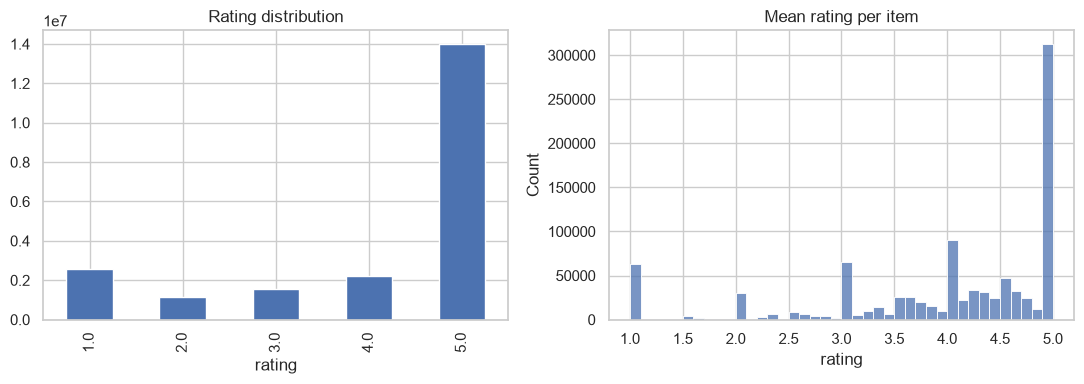

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
reviews["rating"].value_counts().sort_index().plot.bar(ax=axes[0], title="Rating distribution")
sns.histplot(reviews.groupby("parent_asin")["rating"].mean(), bins=40, ax=axes[1])
axes[1].set_title("Mean rating per item")
plt.tight_layout(); plt.show()

### 2.2 The long tail: item popularity, Lorenz curve, Gini
**Why:** This is the core of your project. You need a baseline measure of how concentrated the *data* is, so you can later say whether each model's recommendations are *more* concentrated (amplification) or less.

- **Gini coefficient:** 0 = every item equally popular, 1 = one item gets everything.
- **Short head / long tail:** following Abdollahpouri et al., the *head* is the most popular items that together account for 20% of interactions. These labels are reused later for metrics like APLT (share of long-tail items in recommendations).

Gini=0.859 | head items: 1,392 (0.14% of items -> 20% of interactions)


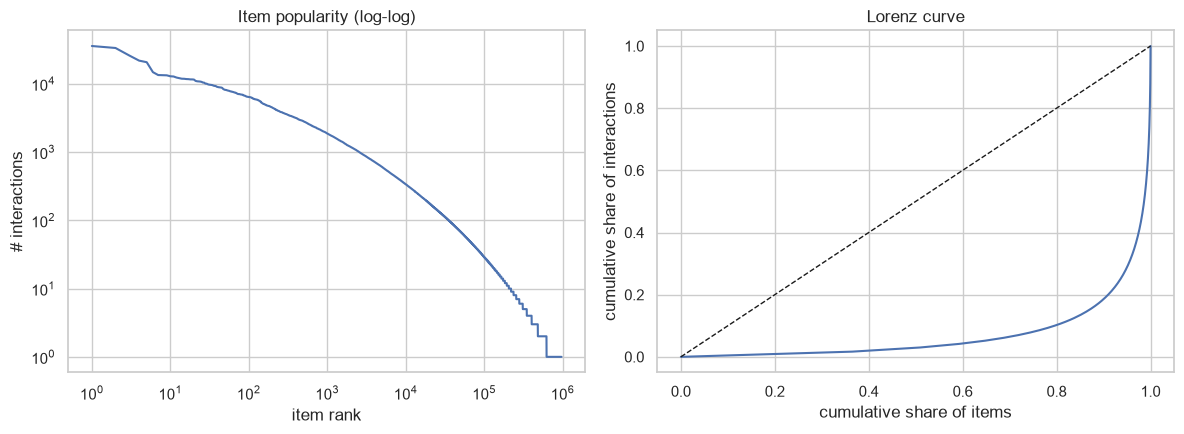

In [32]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n, cum = len(x), np.cumsum(x)
    return (n + 1 - 2 * (cum / cum[-1]).sum()) / n

def head_tail(df, head_share=0.20):
    counts = df["parent_asin"].value_counts()            # sorted descending
    cum = counts.cumsum() / counts.sum()
    head = set(cum[cum <= head_share].index) or {counts.index[0]}
    return counts, head

def lorenz(counts):
    x = np.sort(counts.values)
    y = np.insert(np.cumsum(x) / x.sum(), 0, 0)
    return np.linspace(0, 1, len(y)), y

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

counts, head = head_tail(interactions)
print(f"Gini={gini(counts):.3f} | head items: {len(head):,} "
      f"({len(head)/len(counts):.2%} of items -> 20% of interactions)")

axes[0].loglog(np.arange(1, len(counts) + 1), counts.values)
axes[1].plot(*lorenz(counts))
axes[0].set(title="Item popularity (log-log)", xlabel="item rank", ylabel="# interactions")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set(title="Lorenz curve", xlabel="cumulative share of items",
            ylabel="cumulative share of interactions")
plt.tight_layout(); plt.show()

item_counts, HEAD_ITEMS = head_tail(interactions)

### 2.3 User activity & cold start
**Why:** If most users have 1–2 interactions, leave-one-out evaluation leaves them with almost no training history. This tells you how much k-core you need and how many users you'll actually be able to evaluate.

Users with exactly 1 interaction: 63.10%
count    1.081463e+07
mean     1.988135e+00
std      2.557523e+00
min      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
90%      4.000000e+00
99%      1.200000e+01
max      4.190000e+02
Name: count, dtype: float64


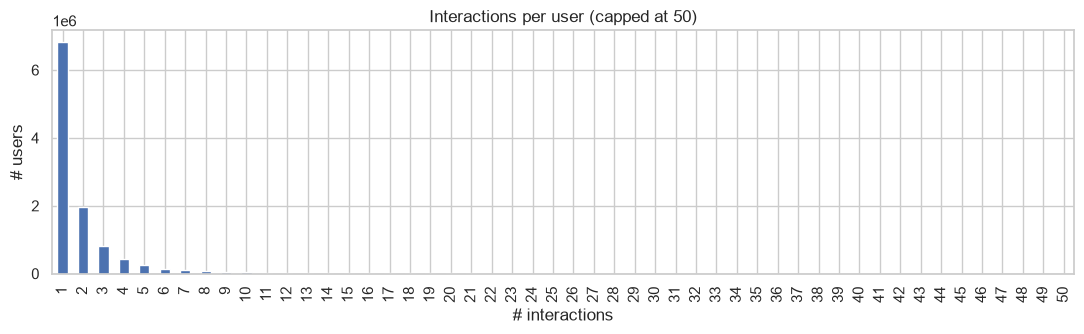

In [33]:
user_counts = interactions["user_id"].value_counts()
print(f"Users with exactly 1 interaction: {(user_counts == 1).mean():.2%}")
print(user_counts.describe(percentiles=[.5, .75, .9, .99]))

ax = user_counts.clip(upper=50).value_counts().sort_index().plot.bar(figsize=(11, 3.5))
ax.set(title="Interactions per user (capped at 50)", xlabel="# interactions", ylabel="# users")
plt.tight_layout(); plt.show()

### 2.4 How mainstream is each user?
**Why:** Popularity bias doesn't hit everyone equally. Users with niche taste suffer most when a model pushes popular items (Abdollahpouri et al., *The Unfairness of Popularity Bias*). Profiling users now lets you later compare model accuracy for niche vs. mainstream users.

            avg_item_pop  tail_ratio
group                               
mainstream   3407.045147    0.357328
diverse       316.687539    1.000000
niche         316.884229    1.000000


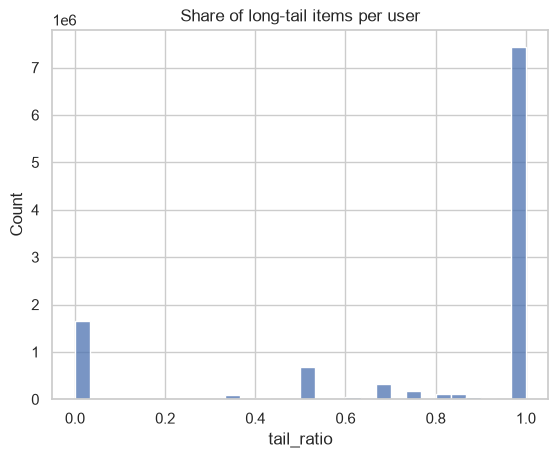

In [34]:
pop = interactions["parent_asin"].map(item_counts)
user_profile = (interactions.assign(item_pop=pop, is_tail=~interactions["parent_asin"].isin(HEAD_ITEMS))
                    .groupby("user_id")
                    .agg(avg_item_pop=("item_pop", "mean"), tail_ratio=("is_tail", "mean")))

user_profile["group"] = pd.qcut(user_profile["tail_ratio"].rank(method="first"), 3,
                                labels=["mainstream", "diverse", "niche"])
print(user_profile.groupby("group", observed=True)[["avg_item_pop", "tail_ratio"]].mean())
sns.histplot(user_profile["tail_ratio"], bins=30).set(title="Share of long-tail items per user")
plt.show()

### 2.5 Popularity vs. quality
**Why:** If popular items are also the best-rated, recommending them is partly justified. If there's little correlation, popularity bias is pushing items that are merely *visible*, which strengthens your motivation.

Spearman(popularity, mean rating) = -0.164 (p=0)


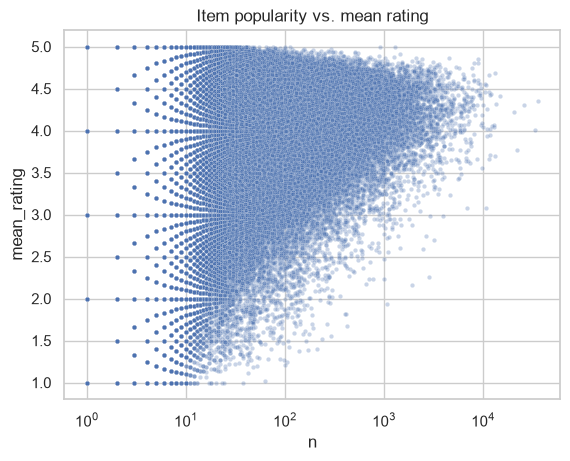

In [35]:
item_stats = interactions.groupby("parent_asin")["rating"].agg(n="count", mean_rating="mean")
rho, p = spearmanr(item_stats["n"], item_stats["mean_rating"])
print(f"Spearman(popularity, mean rating) = {rho:.3f} (p={p:.2g})")

ax = sns.scatterplot(data=item_stats, x="n", y="mean_rating", alpha=0.3, s=10)
ax.set(xscale="log", title="Item popularity vs. mean rating")
plt.show()

### 2.6 Time
**Why:** (a) Shows whether some years dominate the data. (b) Justifies a **temporal split**: random splits let models train on the future, which inflates accuracy and especially favours items that later became popular.

           interactions      gini
timestamp                        
2000                  2  0.000000
2001                  8  0.166667
2002                 19  0.092879
2003                 66  0.379679
2004                178  0.341777
2005                648  0.370160
2006               1085  0.390276
2007               3942  0.420249
2008               6148  0.399436
2009              12088  0.420627
2010              29143  0.474279
2011              65186  0.541636
2012             142328  0.589331
2013             449941  0.689015
2014             738704  0.729394
2015            1307672  0.763628
2016            1547208  0.767535
2017            1583968  0.767667
2018            1756391  0.765024
2019            2419443  0.783993
2020            3322200  0.800472
2021            3456340  0.790854
2022            3222018  0.786310
2023            1436220  0.736259


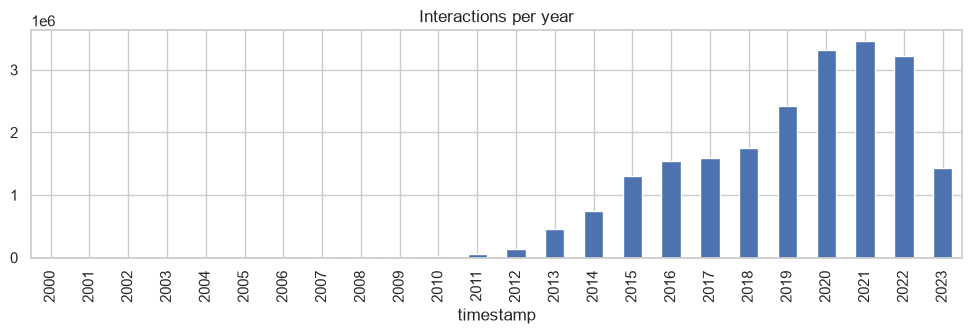

In [36]:
yearly = interactions.groupby(interactions["timestamp"].dt.year).agg(
    interactions=("user_id", "size"),
    gini=("parent_asin", lambda s: gini(s.value_counts())))
print(yearly)
yearly["interactions"].plot.bar(figsize=(10, 3.5), title="Interactions per year")
plt.tight_layout(); plt.show()

### 2.7 Store concentration (ties to your motivation)
**Why:** Your proposal cites the claim that ~2% of sellers drive >50% of revenue. You can check the review-level equivalent in your own data, which is a stronger motivation statement than an external blog.

In [37]:
m = interactions.merge(meta[["parent_asin", "store", "price", "main_category"]], on="parent_asin", how="left")
store_counts = m["store"].dropna().value_counts()
top = max(1, int(len(store_counts) * 0.02))
print(f"Top 2% of stores ({top:,}) account for {store_counts.iloc[:top].sum()/store_counts.sum():.2%} of reviews")
print(f"Store Gini: {gini(store_counts):.3f} | reviews with no store: {m['store'].isna().mean():.2%}")

Top 2% of stores (2,395) account for 68.84% of reviews
Store Gini: 0.928 | reviews with no store: 5.70%


### 2.8 Price vs. popularity
**Why:** If popular items cluster at low prices, a niche-boosting model may also shift recommendations toward pricier items. Useful context for discussing trade-offs.

In [38]:
pp = item_stats.join(meta.set_index("parent_asin")["price"]).dropna(subset=["price"])
print(f"Items with a price: {len(pp)/len(item_stats):.2%}")
if len(pp) > 10:
    pp["price_bin"] = pd.qcut(pp["price"], 5, duplicates="drop")
    print(pp.groupby("price_bin", observed=True)["n"].agg(["median", "mean", "count"]))

Items with a price: 37.28%
                 median       mean  count
price_bin                                
(-0.001, 8.99]      4.0  39.960742  80366
(8.99, 12.99]       4.0  40.792099  66647
(12.99, 19.99]      5.0  47.133411  75961
(19.99, 33.8]       5.0  47.286837  65511
(33.8, 9999.99]     4.0  35.715764  72109


## 3. Train/test split & save
Temporal leave-last-out: each user's **most recent** interaction goes to test. Test items never seen in training are dropped, because CF/MF can't score unseen items. Report how many you drop.

In [1]:
import duckdb
from pathlib import Path

# ---------- Configuration ----------
DATA_DIR = Path(r"D:\CS4100\group project\popularity-bias-recsys\data\interim")
CATEGORY = "Beauty_and_Personal_Care"
DEDUP_PATH = DATA_DIR / f"{CATEGORY}_dedup.parquet"   # output of the dedup step

out = DATA_DIR / "processed"
out.mkdir(parents=True, exist_ok=True)
tmp = DATA_DIR / "duckdb_tmp"
tmp.mkdir(exist_ok=True)

con = duckdb.connect()
con.execute("SET memory_limit='8GB'")                    # adjust to your machine; keep below ~half of RAM
con.execute(f"SET temp_directory='{tmp.as_posix()}'")    # spill to D: drive instead of C:

# ---------- 1. Load deduplicated data, keep verified purchases only ----------
# DuckDB reads the parquet lazily, so the whole file never has to fit in pandas memory.
con.execute(f"""
    CREATE TEMP TABLE base AS
    SELECT user_id, parent_asin, rating, epoch_ms(timestamp) AS timestamp
    FROM read_parquet('{DEDUP_PATH.as_posix()}')
    WHERE verified_purchase
""")

# ---------- 2. Rank each user's interactions from newest to oldest ----------
# rn = 1 is the user's most recent interaction (goes to test).
# parent_asin is a secondary sort key so that timestamp ties are broken deterministically.
con.execute("""
    CREATE TEMP TABLE ranked AS
    SELECT *, ROW_NUMBER() OVER (
        PARTITION BY user_id ORDER BY timestamp DESC, parent_asin DESC) AS rn
    FROM base
""")

# ---------- 3. Training set: everything except each user's last interaction ----------
con.execute("""
    CREATE TEMP TABLE train AS
    SELECT user_id, parent_asin, rating, timestamp FROM ranked WHERE rn > 1
""")

# ---------- 4. Test set: each user's last interaction ----------
# Keep a test row only if both its user and its item appear in train,
# because CF / MF models cannot score users or items they have never seen.
con.execute("""
    CREATE TEMP TABLE test AS
    SELECT user_id, parent_asin, rating, timestamp FROM ranked
    WHERE rn = 1
      AND user_id     IN (SELECT DISTINCT user_id     FROM train)
      AND parent_asin IN (SELECT DISTINCT parent_asin FROM train)
""")

# ---------- 5. Head items, recomputed on TRAIN only ----------
# Head = most popular items that together account for 20% of training interactions.
# Using train (not the full data) avoids leaking test-period popularity into the definition.
con.execute("""
    CREATE TEMP TABLE head_items AS
    SELECT parent_asin FROM (
        SELECT parent_asin,
               SUM(cnt) OVER (ORDER BY cnt DESC, parent_asin) * 1.0 / SUM(cnt) OVER () AS cum
        FROM (SELECT parent_asin, COUNT(*) AS cnt FROM train GROUP BY parent_asin)
    ) WHERE cum <= 0.2
""")

# ---------- 6. Report how much data was dropped ----------
n_base, n_users = con.execute("SELECT COUNT(*), COUNT(DISTINCT user_id) FROM base").fetchone()
n_train = con.execute("SELECT COUNT(*) FROM train").fetchone()[0]
n_train_users = con.execute("SELECT COUNT(DISTINCT user_id) FROM train").fetchone()[0]
n_test = con.execute("SELECT COUNT(*) FROM test").fetchone()[0]
n_head = con.execute("SELECT COUNT(*) FROM head_items").fetchone()[0]
print(f"Total interactions: {n_base:,} | total users: {n_users:,}")
print(f"train: {n_train:,} rows | test: {n_test:,} rows | head items: {n_head:,}")
print(f"Dropped: users with only 1 interaction = {n_users - n_train_users:,}; "
      f"users whose test item is unseen in train = {n_train_users - n_test:,}")

# ---------- 7. Sanity checks (all three should be 0) ----------
# (a) No (user, item) pair may appear in both train and test.
print("Train/test (user, item) overlap:", con.execute(
    "SELECT COUNT(*) FROM test JOIN train USING (user_id, parent_asin)").fetchone()[0])

# (b) No duplicated (user, item) pairs inside train.
print("Duplicated (user, item) pairs in train:", con.execute(
    "SELECT COUNT(*) FROM (SELECT 1 FROM train GROUP BY user_id, parent_asin HAVING COUNT(*) > 1)"
).fetchone()[0])

# (c) Each test interaction must not be earlier than the user's latest train interaction.
print("Temporal order violations:", con.execute("""
    SELECT COUNT(*) FROM test t
    JOIN (SELECT user_id, MAX(timestamp) AS m FROM train GROUP BY user_id) r USING (user_id)
    WHERE t.timestamp < r.m""").fetchone()[0])

# ---------- 8. Save (CSV for compatibility, parquet for fast loading) ----------
for name in ["train", "test", "head_items"]:
    con.execute(f"COPY {name} TO '{(out / f'{CATEGORY}_{name}.csv').as_posix()}' (HEADER, DELIMITER ',')")
    con.execute(f"COPY {name} TO '{(out / f'{CATEGORY}_{name}.parquet').as_posix()}' (FORMAT PARQUET)")
con.close()
print("saved to", out)

Total interactions: 21,500,946 | total users: 10,814,629
train: 10,686,317 rows | test: 3,874,667 rows | head items: 1,554
Dropped: users with only 1 interaction = 6,823,616; users whose test item is unseen in train = 116,346
Train/test (user, item) overlap: 0
Duplicated (user, item) pairs in train: 0
Temporal order violations: 0
saved to D:\CS4100\group project\popularity-bias-recsys\data\interim\processed


## 4. Cross-category comparison
Run the profile below on each category so all three appear in one table. Different Gini / head shares across categories give you a hypothesis to test: *does bias amplification grow with how concentrated the data already is?*

`max_rows` lets you sample the very large categories (Clothing, Shoes & Jewelry has tens of millions of reviews) on a laptop. Use the same sampling rule for every category.

In [ ]:
def profile_category(cat, max_rows=None, k=5):
    r = pd.read_parquet(
        DATA_DIR / f"{cat}_full.parquet",
        columns=["user_id", "parent_asin", "rating", "timestamp", "verified_purchase"]
    )
    if ONLY_VERIFIED:
        r = r[r["verified_purchase"] == True]
    r = r.drop_duplicates(["user_id", "parent_asin"], keep="last")
    row = summarize(r, cat)
    counts, head = head_tail(r)
    row["gini_raw"] = gini(r["parent_asin"].value_counts())
    row["gini_core"] = gini(counts)
    row["head_item_share"] = len(head) / len(counts) if len(counts) else np.nan
    row["mean_rating"] = r["rating"].mean()
    return row

CATEGORIES = ["Beauty_and_Personal_Care"]   # add the others once downloaded
comparison = pd.concat([profile_category(c) for c in CATEGORIES], axis=1).T
comparison